# Notebook 2: Parameter Estimation from Concentration Data

This notebook demonstrates parameter estimation from noisy concentration
measurements. The data are synthetic: we compute the exact solution of the
reaction with known rate constants and add Gaussian noise, so we can check how
well the estimates recover the truth.

**Reaction system:** A → B → C  
**Goal:** Recover rate constants k1 and k2 from noisy concentration measurements

In [1]:
import sys
sys.path.insert(0, '..')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import kipetax

## Generate synthetic concentration data

For first-order A → B → C starting from pure A, the concentrations have a
closed form, so the "true" data do not depend on kipetax's own solver. We
sample 300 times on [0, 10] and add Gaussian noise with standard deviation
σ = 0.01. The result is a DataFrame with time as the index and one column per
component, which is the format `add_data` expects.

In [2]:
def abc_exact(t, k1, k2, A0=1.0):
    """Exact solution of A -> B -> C (first order, k1 != k2), starting from pure A."""
    A = A0 * np.exp(-k1 * t)
    B = A0 * k1 / (k2 - k1) * (np.exp(-k1 * t) - np.exp(-k2 * t))
    return A, B, A0 - A - B


K1_TRUE, K2_TRUE = 1.5, 0.3
SIGMA = 0.01                      # measurement noise standard deviation

rng = np.random.default_rng(2026)   # fixed seed: reproducible data
t = np.linspace(0.0, 10.0, 300)
C_true = pd.DataFrame(dict(zip('ABC', abc_exact(t, K1_TRUE, K2_TRUE))), index=t)
C_data = C_true + rng.normal(0.0, SIGMA, C_true.shape)

print(f"Data shape: {C_data.shape}  (times × components)")
print(f"Time range: {C_data.index[0]:.3f} to {C_data.index[-1]:.3f}")
print(f"Components: {list(C_data.columns)}")
C_data.head()

Data shape: (300, 3)  (times × components)
Time range: 0.000 to 10.000
Components: ['A', 'B', 'C']


,A,B,C
0.000000,0.992069,0.002406,-0.018963
0.033445,0.965028,0.055066,-0.002674
0.066890,0.901415,0.097536,-0.001709
0.100334,0.858017,0.144791,0.007281
0.133779,0.817542,0.177242,0.005329


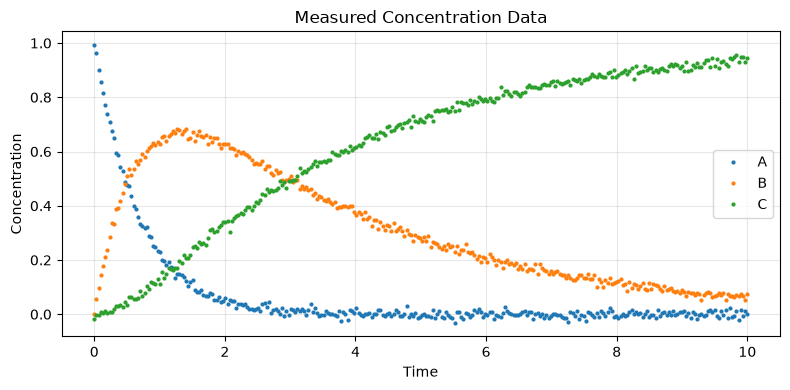

In [3]:
fig, ax = plt.subplots(figsize=(8, 4))
for comp in C_data.columns:
    ax.plot(C_data.index, C_data[comp], '.', label=comp, markersize=4)
ax.set_xlabel('Time')
ax.set_ylabel('Concentration')
ax.set_title('Measured Concentration Data')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Build the reaction model

We use initial guesses for k1 and k2 and let the optimizer find the true values.

In [4]:
r1 = kipetax.ReactionModel('conc-pe')

# Parameters with initial guesses and bounds
k1 = r1.parameter('k1', value=0.5, bounds=(0.01, 10.0))
k2 = r1.parameter('k2', value=0.1, bounds=(0.01, 5.0))

# Initial conditions: the reactor is charged with pure A. Use the known charge,
# not the first (noisy) sample: noise can make a measured zero concentration
# slightly negative, which is infeasible for a concentration bounded below by 0.
A = r1.component('A', value=1.0)
B = r1.component('B', value=0.0)
C = r1.component('C', value=0.0)

# ODEs: A → B → C
r1.add_ode('A', -k1 * A)
r1.add_ode('B',  k1 * A - k2 * B)
r1.add_ode('C',  k2 * B)

# Add the concentration data
r1.add_data(name='conc_data', data=C_data)

# Set discretization (finer than the data sampling)
r1.set_discretization(nfe=60, ncp=3)

print("Model built successfully")
print(f"Time span: 0 to {C_data.index[-1]:.2f}")

Model built successfully
Time span: 0 to 10.00


## Run parameter estimation

We provide known (or estimated) variances for each component measurement.

In [5]:
# Measurement variances. Here we know them exactly (we generated the noise);
# with real data, estimate them from replicates or with run_variance_estimator().
variances = {'A': SIGMA**2, 'B': SIGMA**2, 'C': SIGMA**2}

r1.run_opt(variances=variances)
ro = r1.results_dict['p_estimator']
print(f"Optimization status: {ro.status}")

Parameter estimation complete: status=optimal
  k1                   = 1.49945
  k2                   = 0.300221
Optimization status: optimal


## Results

In [6]:
truth = {'k1': K1_TRUE, 'k2': K2_TRUE}
print(f"{'':4s}{'estimate':>12s}{'true':>10s}{'rel. err':>12s}")
for name, val in ro.P.items():
    print(f"{name:4s}{val:12.5f}{truth[name]:10.3f}{abs(val - truth[name]) / truth[name]:12.2e}")

print(f"\nObjective value: {ro.objective:.4e}")

        estimate      true    rel. err
k1       1.49945     1.500    3.66e-04
k2       0.30022     0.300    7.35e-04

Objective value: 9.6245e+02


## Compare fitted trajectories to measurements

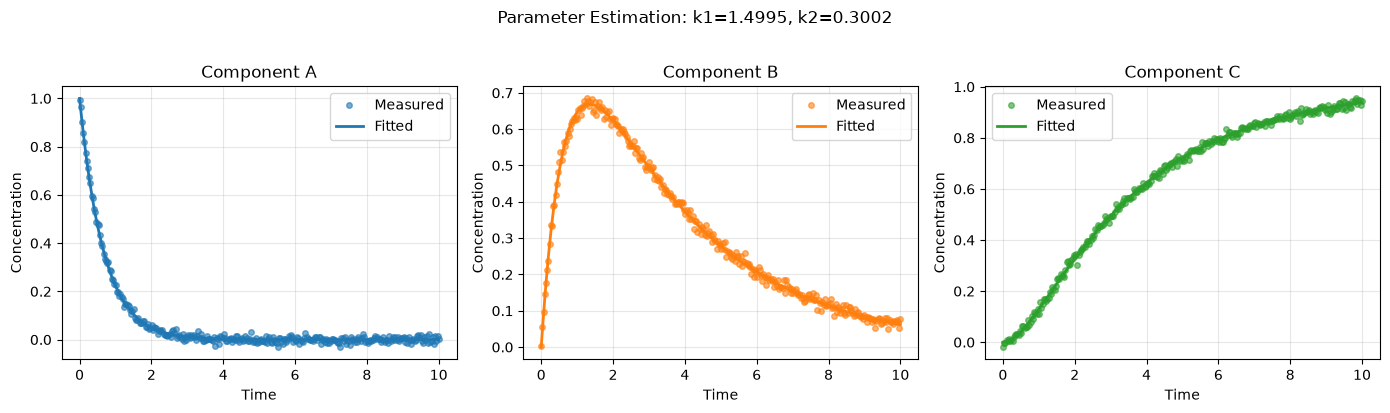

In [7]:
Z = ro.Z  # Fitted concentration profiles

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
colors = {'A': 'tab:blue', 'B': 'tab:orange', 'C': 'tab:green'}

for ax, comp in zip(axes, ['A', 'B', 'C']):
    color = colors[comp]
    # Measurements
    ax.plot(C_data.index, C_data[comp], 'o', color=color, markersize=4,
            alpha=0.6, label='Measured')
    # Fitted profile
    ax.plot(Z.index, Z[comp], '-', color=color, linewidth=2, label='Fitted')
    ax.set_xlabel('Time')
    ax.set_ylabel('Concentration')
    ax.set_title(f'Component {comp}')
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.suptitle(
    f'Parameter Estimation: k1={ro.P["k1"]:.4f}, k2={ro.P["k2"]:.4f}',
    y=1.02
)
plt.tight_layout()
plt.show()

## Residuals analysis

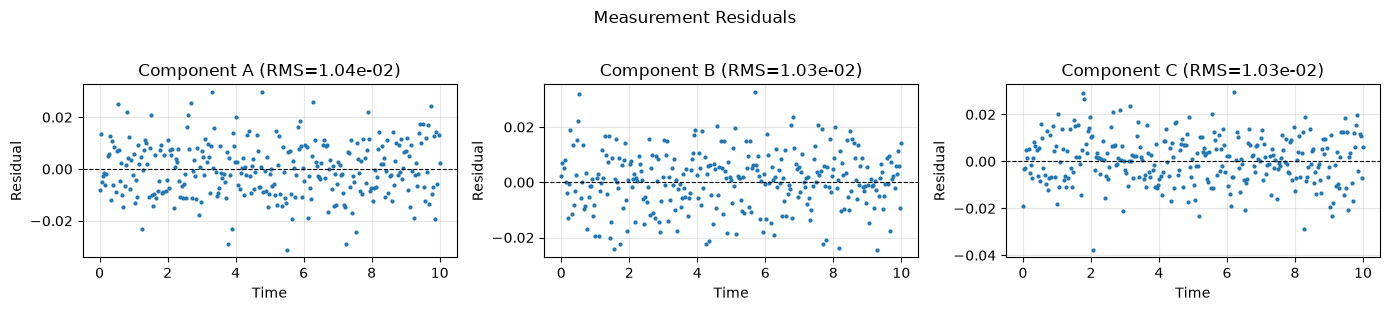

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3))

for ax, comp in zip(axes, ['A', 'B', 'C']):
    # Interpolate fitted profile to measurement times
    fitted_at_meas = np.interp(C_data.index, Z.index, Z[comp])
    residuals = C_data[comp].values - fitted_at_meas
    ax.plot(C_data.index, residuals, '.', markersize=4)
    ax.axhline(0, color='k', linewidth=0.8, linestyle='--')
    ax.set_xlabel('Time')
    ax.set_ylabel('Residual')
    ax.set_title(f'Component {comp} (RMS={np.sqrt(np.mean(residuals**2)):.2e})')
    ax.grid(True, alpha=0.3)

plt.suptitle('Measurement Residuals', y=1.02)
plt.tight_layout()
plt.show()